In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cd '/content/drive/MyDrive/mood_therapy'

In [ ]:
#@title
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import MaxPooling2D
import numpy as np
import tensorflow as tf

In [ ]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import Image
import random
import pywt
import PIL

In [ ]:
#@title
def create_model():
    model = Sequential()
    model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(48,48,1)))
    model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.25))
    model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.25))
    model.add(Flatten())
    model.add(Dense(1024, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(7, activation='softmax'))

    model.load_weights('/content/drive/MyDrive/mood_therapy/model.h5')

    return model

In [ ]:
#@title
interpreter = create_model()

In [ ]:
def get_grayscale(img):
    return img[:,:,0]/224+img[:,:,1]/224+img[:,:,2]/224

In [ ]:
def get_stationary_wavelet_entropy(img_gray):
    coeffs = pywt.swtn( data = img_gray, wavelet = 'haar', level = 4, start_level = 0, trim_approx = True, axes=[0,1] )
    entropy = []
    band_cat = ['ad','da','dd']
    for i in range(len(coeffs)):
        if i==0:
            for j in range(len(coeffs[i])):
                band = coeffs[i][j]
                band = band.flatten()
                band_entropy = -np.nansum(band**2 * np.log2(band**2,where =  band != 0))
                entropy.append(band_entropy)
        else :
            for j in band_cat:
                band = coeffs[i][j]
                band = band.flatten()
                band_entropy = -np.nansum(band**2 * np.log2(band**2,where =  band != 0))
                entropy.append(band_entropy)
    return entropy

In [ ]:
def get_features(image):
    img_gray = get_grayscale(image)
    entropy = get_stationary_wavelet_entropy(img_gray)
    return entropy

In [ ]:
def get_predicted(prediction):
    y_pred = []
    for predicted in prediction:
        if predicted>0.1:
            y_pred.append(1)
        else :
            y_pred.append(0)
    return y_pred

In [ ]:
emotion_mapping = {
    1  : 'Peace',
    2  : 'Affection',
    3  : 'Esteem',
    4  : 'Anticipation',
    5  : 'Engagement',
    6  : 'Confidence',
    7  : 'Happiness',
    8  : 'Pleasure',
    9  : 'Excitement',
    10 : 'Surprise',
    11 : 'Sympathy',
    12 : 'Doubt/Confusion',
    13 : 'Disconnection',
    14 : 'Fatigue',
    15 : 'Embarrassment',
    16 : 'Yearning',
    17 : 'Disapproval',
    18 : 'Aversion',
    19 : 'Annoyance',
    20 : 'Anger',
    21 : 'Sensitivity',
    22 : 'Sadness',
    23 : 'Disquietment',
    24 : 'Fear',
    25 : 'Pain',
    26 : 'Suffering'
}

In [ ]:
emotion_dict = {0: "Anger", 1: "Embarrassment", 2: "Fear", 3: "Happiness", 4: "Disconnection", 5: "Sadness", 6: "Surprise"}

In [ ]:
emotion_playlist = {
    'Peace'             : 'https://open.spotify.com/playlist/3WkLqvDQoIBVN3yhldrB6y?si=4724adf78526475d',
    'Affection'         : 'https://open.spotify.com/playlist/7HqauKS07jjRiWIL1tOv04?si=2d4a905f7e404439',
    'Esteem'            : 'https://open.spotify.com/playlist/3WrfkqANy0YcKNEycV6TUT?si=3a393923d97a4bbb',
    'Anticipation'      : 'https://open.spotify.com/playlist/0IusjjCCu02UMxOlrWLclP?si=a4dcc9d2cf2c4762',
    'Engagement'        : 'https://open.spotify.com/playlist/4LqhjH8JTTlua6EZvG78hU?si=998e4a8815c94a56',
    'Confidence'        : 'https://open.spotify.com/playlist/6fzpuuOf0b2iJNxn91vRnJ?si=d19073b30e0b43b3',
    'Happiness'         : 'https://open.spotify.com/playlist/7HqauKS07jjRiWIL1tOv04?si=5eb8821e73db46dc',
    'Pleasure'          : 'https://open.spotify.com/playlist/4mPr8pTNABKD3SfCknvhxy?si=ac971ac1e6a048a3',
    'Excitement'        : 'https://open.spotify.com/playlist/4uwGrrNc3Cyl8zz9jKBq35?si=fb86831c879e4b06',
    'Surprise'          : 'https://open.spotify.com/playlist/7hKb64k5os0UlhfubUFpM0?si=521acde84df440f1',
    'Sympathy'          : 'https://open.spotify.com/playlist/3IftKVQH2Hr5YynIEuAI7S?si=c14e5f4a4b054ed4',
    'Doubt/Confusion'   : 'https://open.spotify.com/playlist/4xDtaWZ3SuVxslRZi4mN6f?si=8747781d8a3849b5',
    'Disconnection'     : 'https://open.spotify.com/playlist/4xDtaWZ3SuVxslRZi4mN6f?si=8747781d8a3849b5',
    'Fatigue'           : 'https://open.spotify.com/playlist/7mvdvn7LkiC7JyJOgUBZ4C?si=162f1eb58e054759',
    'Embarrassment'     : 'https://open.spotify.com/playlist/3TtFl1m1PD5iFu4zj8XgHd?si=f97bf25ffa3d4680',
    'Yearning'          : 'https://open.spotify.com/playlist/2BedOXLE2oA2KXdq75dDmT?si=b18badb3a6934988',
    'Disapproval'       : 'https://open.spotify.com/playlist/3k5T8gBYNuLp3RObImAxot?si=44c1b8f990214256',
    'Aversion'          : 'https://open.spotify.com/playlist/6bZFk5mLrGts5yFSXECR6v?si=187bcf09c80f4705',
    'Annoyance'         : 'https://open.spotify.com/playlist/6fzpuuOf0b2iJNxn91vRnJ?si=d8e70fcdd43144ae',
    'Anger'             : 'https://open.spotify.com/playlist/7kOcgryzQOw0GdOczDI8Mp?si=6a49d745819c459a',
    'Sensitivity'       : 'https://open.spotify.com/playlist/0zvvL2WqDaT8KRK1QtdPVg?si=d9abc583d4544c13',
    'Sadness'           : 'https://open.spotify.com/playlist/3yGRncfVkANbbBp000qP1m?si=1928b8c43ac04d88',
    'Disquietment'      : 'https://open.spotify.com/playlist/1CAbq0weZcna6wdAU1ZVwW?si=e83acc2a6a08471c',
    'Fear'              : 'https://open.spotify.com/playlist/3U732mnt7VRkE2IZDUDFDS?si=a3a96033bf5e4104',
    'Pain'              : 'https://open.spotify.com/playlist/53nirCP388i82OJKYCOaY2?si=ebe8c5fd3d5f465b',
    'Suffering'         : 'https://open.spotify.com/playlist/53nirCP388i82OJKYCOaY2?si=ebe8c5fd3d5f465b'
}

In [ ]:
def get_emotion(filename):
    im = cv2.imread(filename)
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    facecasc = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
    faces = facecasc.detectMultiScale(gray,scaleFactor=1.3, minNeighbors=5)
    for (x, y, w, h) in faces:
            # cv2.rectangle(gray, (x, y-50), (x+w, y+h+10), (255, 0, 0), 2)
            # plt.imshow(gray,cmap='gray')
            roi_gray = gray[y:y + h, x:x + w]
            cropped_img = np.expand_dims(np.expand_dims(cv2.resize(roi_gray, (48, 48)), -1), 0)
            prediction = interpreter.predict(cropped_img)
            maxindex = int(np.argmax(prediction))
            return(emotion_dict[maxindex])

In [ ]:
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

1/1 [==============================] - 0s 25ms/step
Happiness
https://open.spotify.com/playlist/7HqauKS07jjRiWIL1tOv04?si=5eb8821e73db46dc


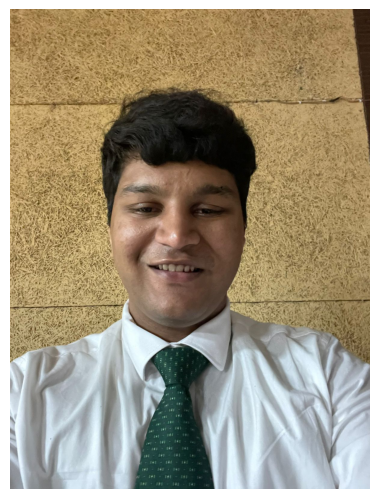

In [ ]:
try:
    # filename = take_photo()
    # print('Saved to {}'.format(filename))
    filename = '/content/siddharth.jpeg'

    im = PIL.Image.open(filename)
    plt.axis('off')
    plt.tight_layout(pad=0, w_pad=0, h_pad=0)
    plt.imshow(im,cmap='gray')

    emo = get_emotion(filename)
    print(emo)
    playlist = emotion_playlist[emo]
    print(playlist)
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
        print(str(err))